# Proyecto Integrador · Parte II — Similitud (tareas 5 a 8)
## Shingles, Jaccard, MinHash y LSH sobre los textos de las contrataciones públicas

**Qué hace este notebook**
1. **Tarea 5:** convierte cada texto en un *conjunto de shingles* (pares de palabras seguidas).
2. **Tarea 6:** compara el Jaccard **exacto** con su aproximación por **MinHash**.
3. **Tarea 7:** aplica **LSH** (bandas y filas) y mide falsos positivos y falsos negativos.
4. **Tarea 8:** interpreta casos reales de textos similares.

**Entrada:** los Parquet de la limpieza (tabla `procesos`). **Salida:** tablas y gráficos aquí, y archivos JSON para la página web en `web_artefactos/`.

**Spark se usa en todo lo pesado** (shingles, firmas, comparación de pares, LSH). El código es simple a propósito: una idea por celda.

### Los cuatro conceptos en un minuto
- **Shingle:** un pedazo del texto. Aquí, dos palabras seguidas. `"servicio de supervision"` tiene los shingles `"servicio de"` y `"de supervision"`.
- **Jaccard:** qué tan parecidos son dos conjuntos = (shingles en común) ÷ (shingles en total). Va de 0 (nada en común) a 1 (iguales).
- **MinHash:** resume el conjunto de shingles en una *firma* de 128 números. Si dos textos se parecen, sus firmas coinciden en muchas posiciones, y esa fracción estima el Jaccard.
- **LSH:** para no comparar todos los pares, corta la firma en *b bandas* de *r* números. Dos textos son **candidatos** si coinciden en alguna banda completa. Solo se verifican los candidatos.

## 0. Configuración

In [1]:
import os, json, time, shutil, subprocess, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

USAR_DRIVE   = True
RUTA_PARQUET = "/content/drive/MyDrive/proyecto_integrador_seace/parquet"      # carpeta que dejó la limpieza
SALIDA       = "/content/drive/MyDrive/proyecto_integrador_seace/similitud"    # aquí se guardan los resultados
WEB_BASE     = "/content/drive/MyDrive/proyecto_integrador_seace/web_artefactos"   # carpeta de archivos JSON para la página web
WEB          = f"{WEB_BASE}/similitud"

N_HASH  = 128      # largo de la firma MinHash
SEED    = 42       # semilla: con la misma semilla salen los mismos resultados
K_LISTA = [8, 16, 32, 64, 128]                        # cuántos hashes usar al estimar Jaccard (tarea 6)
UMBRALES = [0.5, 0.6, 0.7, 0.8, 0.9]                  # "similar" = Jaccard mayor o igual a esto (tarea 7)
CONFIGS  = [(128, 1), (64, 2), (42, 3), (32, 4), (25, 5), (21, 6), (16, 8), (12, 10), (10, 12), (8, 16)]   # (bandas, filas)
LSH_FINAL = (21, 6)                                   # configuración que se usa con todos los textos
ENTIDAD_S = "PE-CONSUCODE-2543"                       # entidad del subconjunto de evaluación: Seguro Social de Salud (EsSalud)

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(WEB, exist_ok=True)
print("Resultados en:", SALIDA)

Mounted at /content/drive
Resultados en: /content/drive/MyDrive/proyecto_integrador_seace/similitud


In [2]:
# Java y Spark (en Colab ya suelen estar)
if shutil.which("java") is None:
    subprocess.run("apt-get -qq install -y openjdk-17-jre-headless", shell=True, check=True)
subprocess.run("pip -q install pyspark==3.5.3", shell=True, check=True)

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.ml.feature import NGram, HashingTF, MinHashLSH

spark = (SparkSession.builder.master("local[*]").appName("similitud")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
print("Spark", spark.version)

Spark 3.5.3


In [3]:
# Función para guardar un JSON con dos partes: "meta" (qué es) y "datos" (la lista de registros)
def a_registros(df):
    df = df.astype(object).where(pd.notnull(df), None)
    return df.to_dict("records")

def guardar_json(nombre, meta, datos):
    ruta = f"{WEB}/{nombre}"
    with open(ruta, "w", encoding="utf-8") as f:
        json.dump({"meta": meta, "datos": datos}, f, ensure_ascii=False, default=lambda o: o.item())
    print(f"{nombre}: {len(datos)} registros, {os.path.getsize(ruta)/1000:.0f} KB")

## 1. Tarea 5 — Representación: cada texto como conjunto de shingles

**Decisión:** el registro es el **proceso de contratación** y su contenido es la columna `texto` (la descripción ya normalizada: minúsculas, sin tildes).
Cada texto se representa como el conjunto de sus *shingles de palabras*.

In [4]:
procesos = (spark.read.parquet(f"{RUTA_PARQUET}/procesos")
            .select("ocid", "texto", "n_palabras", "entidad_id", "entidad", "entidad_departamento", "fecha_pub", "valor_pen_valido"))
print("procesos:", procesos.count())

procesos: 209740


**Textos repetidos.** Muchos procesos tienen exactamente el mismo texto. Si los comparamos entre sí, todos dan Jaccard 1 y tapan los casos interesantes.
Por eso trabajamos con los **textos distintos**, y los repetidos se analizan aparte (tarea 8).
Además, un texto de una sola palabra no tiene ningún par de palabras seguidas, así que se excluye.

In [5]:
todos = procesos.groupBy("texto").agg(F.count("*").alias("n_procesos"))
textos = (todos.filter(F.size(F.split("texto", " ")) >= 2)
               .withColumn("texto_id", F.row_number().over(Window.orderBy("texto")) - 1)     # un número por texto
               .cache())

n_unicos, n_usados = todos.count(), textos.count()
print("textos distintos:", n_unicos)
print("textos con al menos 2 palabras (los que se usan):", n_usados, f"| se excluyen {n_unicos - n_usados} de una sola palabra")

textos distintos: 163221
textos con al menos 2 palabras (los que se usan): 163208 | se excluyen 13 de una sola palabra


### ¿Qué tipo de shingle conviene? Un experimento simple
Probamos 7 opciones con 1,000 textos. Para cada una medimos:
- **Casi iguales:** el Jaccard entre un texto y el mismo texto con **una palabra cambiada**. Queremos que sea **alto**.
- **Al azar:** el Jaccard entre dos textos cualesquiera. Queremos que sea **bajo**.

El **contraste** (casi iguales − al azar) dice qué tan bien separa la opción lo parecido de lo distinto.

In [6]:
random.seed(SEED)
muestra = textos.orderBy(F.hash("texto")).limit(1000).toPandas()["texto"].tolist()
vocabulario = sorted({palabra for t in muestra for palabra in t.split()})

def shingles(texto, tipo, k):
    if tipo == "palabras":
        p = texto.split()
        return {" ".join(p[i:i+k]) for i in range(max(len(p) - k + 1, 1))}
    return {texto[i:i+k] for i in range(max(len(texto) - k + 1, 1))}

def jaccard(a, b):
    return len(a & b) / len(a | b)

def cambiar_una_palabra(texto):
    p = texto.split()
    p[random.randrange(len(p))] = random.choice(vocabulario)
    return " ".join(p)

casi_iguales = [(t, cambiar_una_palabra(t)) for t in muestra]
al_azar      = [(muestra[i], muestra[(i + 500) % 1000]) for i in range(1000)]

filas = []
for tipo, k in [("palabras", 1), ("palabras", 2), ("palabras", 3), ("palabras", 4), ("caracteres", 4), ("caracteres", 5), ("caracteres", 8)]:
    j_casi = np.mean([jaccard(shingles(a, tipo, k), shingles(b, tipo, k)) for a, b in casi_iguales])
    j_azar = np.array([jaccard(shingles(a, tipo, k), shingles(b, tipo, k)) for a, b in al_azar])
    filas.append({"tipo": f"{tipo} (k={k})", "shingles por texto": np.mean([len(shingles(t, tipo, k)) for t in muestra]),
                  "Jaccard casi iguales": j_casi, "Jaccard al azar": j_azar.mean(),
                  "% al azar con J>0.2": 100 * (j_azar > 0.2).mean(), "contraste": j_casi - j_azar.mean()})
tabla_shingles = pd.DataFrame(filas).round(3)
tabla_shingles

,tipo,shingles por texto,Jaccard casi iguales,Jaccard al azar,% al azar con J>0.2,contraste
0,palabras (k=1),23.582,0.918,0.113,9.2,0.805
1,palabras (k=2),28.781,0.850,0.031,0.2,0.820
2,palabras (k=3),28.582,0.786,0.005,0.0,0.781
3,palabras (k=4),27.726,0.728,0.002,0.0,0.727
4,caracteres (k=4),166.641,0.893,0.101,7.0,0.791
5,caracteres (k=5),175.785,0.882,0.076,3.0,0.806
6,caracteres (k=8),184.354,0.849,0.035,0.2,0.814


### Decisión
Elegimos **palabras de 2 en 2 (k = 2)**.

- Tiene el **mayor contraste** (0.820): un texto con una palabra cambiada sigue dando Jaccard 0.85, y dos textos al azar solo 0.03.
- Apenas el 0.2% de los pares al azar supera Jaccard 0.2. Con palabras sueltas (k = 1) es el 9.2%, y con caracteres de 4 en 4 el 7.0%. Confunden textos distintos que comparten frases comunes como "servicio de" o "adquisicion de".
- Con k = 3 y k = 4 los textos al azar casi no se parecen (0.005 y 0.002), pero un solo cambio de palabra baja mucho el Jaccard (0.79 y 0.73).
- Cada texto genera unos 29 shingles.

In [7]:
# Ejemplo concreto: un texto y sus shingles (pares de palabras seguidas)
ejemplo = muestra[0]
print("TEXTO   :", ejemplo)
print("SHINGLES:", sorted(shingles(ejemplo, "palabras", 2))[:8], "...")
print("TOTAL   :", len(shingles(ejemplo, "palabras", 2)), "shingles")

TEXTO   : servicio de ambulancia aerea para traslado de paciente [nombre omitido] en situacion de emergencia con diagnostico prioridad i y ii a un establecimiento de salud de mayor capacidad resolutiva de la ciudad de lima instituto nacional de salud del nino de lima
SHINGLES: ['a un', 'aerea para', 'ambulancia aerea', 'capacidad resolutiva', 'ciudad de', 'con diagnostico', '[nombre omitido]', 'de ambulancia'] ...
TOTAL   : 41 shingles


### Construir los conjuntos en Spark
Spark hace lo mismo con los 163 mil textos: parte el texto en palabras (`split`), arma los pares (`NGram`) y convierte cada par en un número (`HashingTF`).
El resultado es un vector de ceros y unos donde un 1 significa "este texto tiene ese shingle".

In [8]:
df = textos.withColumn("palabras", F.split("texto", " "))
df = NGram(n=2, inputCol="palabras", outputCol="shingles").transform(df)                              # pares de palabras
df = HashingTF(numFeatures=2**24, binary=True, inputCol="shingles", outputCol="vec").transform(df)     # cada par -> un número
df.select("texto", "shingles", "vec").show(2, truncate=60)

+------------------------------------------------------------+------------------------------------------------------------+------------------------------------------------------------+
|                                                       texto|                                                    shingles|                                                         vec|
+------------------------------------------------------------+------------------------------------------------------------+------------------------------------------------------------+
|00034412 servicio de barrido y limpieza para la ciudad un...|[00034412 servicio, servicio de, de barrido, barrido y, y...|(16777216,[16486,649626,1301583,3351203,3355803,4734061,5...|
|01 servicio de persona natural y o juridica para la super...|[01 servicio, servicio de, de persona, persona natural, n...|(16777216,[793101,869685,1059924,1301583,2022111,2310271,...|
+------------------------------------------------------------+-------------

## 2. Tarea 6 — Jaccard exacto frente a MinHash

### 2.1 Firmas MinHash
Spark calcula la firma de cada texto: 128 números. Las guardamos junto con la lista de shingles (`ids`) para poder calcular el Jaccard exacto.

In [9]:
modelo = MinHashLSH(inputCol="vec", outputCol="hashes", numHashTables=N_HASH, seed=SEED).fit(df)
df = modelo.transform(df)

sacar_ids   = F.udf(lambda v: [int(i) for i in v.indices], "array<int>")       # lista de shingles del texto
sacar_firma = F.udf(lambda hs: [int(h[0]) for h in hs], "array<long>")         # los 128 números de la firma

df = df.select("texto_id", "texto", "n_procesos", "vec", sacar_ids("vec").alias("ids"), sacar_firma("hashes").alias("firma")).cache()
print("textos con firma:", df.count())
df.select("texto_id", F.size("ids").alias("n_shingles"), F.slice("firma", 1, 5).alias("primeros_5_de_la_firma")).show(3, truncate=False)

textos con firma: 163208
+--------+----------+-----------------------------------------------------+
|texto_id|n_shingles|primeros_5_de_la_firma                               |
+--------+----------+-----------------------------------------------------+
|0       |16        |[204044795, 105686480, 8923496, 177309009, 111697767]|
|1       |42        |[45671585, 37134501, 5211122, 97581623, 181450253]   |
|2       |19        |[56120914, 122218596, 205914289, 435906258, 43579392]|
+--------+----------+-----------------------------------------------------+
only showing top 3 rows



### 2.2 Subconjunto para medir con la verdad exacta
Calcular el Jaccard exacto de **todos** los pares de 163 mil textos son 13 mil millones de comparaciones. Por eso usamos un subconjunto: **todos los textos distintos de una entidad grande** (Seguro Social de Salud, EsSalud).
Se eligió porque tiene muchos textos parecidos entre sí. Una muestra aleatoria casi no tendría pares similares y no se podrían medir los falsos negativos.

In [10]:
textos_S = procesos.filter(F.col("entidad_id") == ENTIDAD_S).select("texto").distinct()
S = df.join(textos_S, "texto").select("texto_id", "ids", "firma").cache()
n_S = S.count()
print("textos en el subconjunto:", n_S, "| pares posibles:", f"{n_S*(n_S-1)//2:,}")

textos en el subconjunto: 3493 | pares posibles: 6,098,778


### 2.3 Jaccard exacto de todos los pares del subconjunto
Para cada par contamos los shingles en común (`array_intersect`) y los dividimos por el total (`union`).
Los pares sin ningún shingle en común tienen Jaccard 0 y no se guardan.

In [11]:
izq = S.select(F.col("texto_id").alias("id_a"), F.col("ids").alias("ids_a"))
der = S.select(F.col("texto_id").alias("id_b"), F.col("ids").alias("ids_b"))

pares = (izq.crossJoin(der).filter("id_a < id_b")                                     # cada par una sola vez
            .withColumn("comun", F.size(F.array_intersect("ids_a", "ids_b")))         # shingles en común
            .filter("comun > 0")
            .withColumn("jaccard", F.col("comun") / (F.size("ids_a") + F.size("ids_b") - F.col("comun")))
            .select("id_a", "id_b", "jaccard").cache())

print("pares con algún shingle en común:", f"{pares.count():,}")
verdad = {t: pares.filter(F.col("jaccard") >= t).count() for t in UMBRALES}
print("pares realmente similares (verdad exacta):", verdad)

pares con algún shingle en común: 4,465,947
pares realmente similares (verdad exacta): {0.5: 7599, 0.6: 3906, 0.7: 1569, 0.8: 647, 0.9: 59}


### 2.4 MinHash estima el Jaccard. ¿Con cuánto error?
Tomamos una muestra de pares (hasta 300 por cada tramo de Jaccard: 0–0.1, 0.1–0.2, ...) para ver cómo se comporta en todo el rango.
La estimación con **k hashes** es la fracción de posiciones donde las dos firmas coinciden, mirando solo las primeras k.

In [12]:
tramo  = F.least(F.floor(F.col("jaccard") * 10), F.lit(9)).cast("int")
orden  = Window.partitionBy("tramo").orderBy(F.hash("id_a", "id_b"))
elegidos = pares.withColumn("tramo", tramo).withColumn("n", F.row_number().over(orden)).filter("n <= 300")

firmas = S.select("texto_id", "firma")
elegidos = (elegidos.join(firmas.withColumnRenamed("texto_id", "id_a").withColumnRenamed("firma", "f_a"), "id_a")
                    .join(firmas.withColumnRenamed("texto_id", "id_b").withColumnRenamed("firma", "f_b"), "id_b"))

for k in K_LISTA:
    coinciden = F.size(F.filter(F.zip_with(F.slice("f_a", 1, k), F.slice("f_b", 1, k), lambda x, y: x == y), lambda z: z))
    elegidos = elegidos.withColumn(f"est_k{k}", coinciden / k)

muestra_pares = elegidos.select("id_a", "id_b", "tramo", "jaccard", *[f"est_k{k}" for k in K_LISTA]).toPandas()
print("pares en la muestra:", len(muestra_pares))
muestra_pares.head(5).round(3)

pares en la muestra: 2759


,id_a,id_b,tramo,jaccard,est_k8,est_k16,est_k32,est_k64,est_k128
0,22256,56471,0,0.038,0.125,0.062,0.031,0.016,0.016
1,43724,103884,0,0.014,0.000,0.062,0.031,0.016,0.008
2,7685,103979,0,0.023,0.000,0.062,0.031,0.016,0.016
3,106189,156922,0,0.037,0.000,0.000,0.031,0.047,0.023
4,14987,45963,0,0.067,0.000,0.062,0.062,0.062,0.047


In [13]:
# Error de la estimación para cada k
filas = []
for k in K_LISTA:
    error = (muestra_pares[f"est_k{k}"] - muestra_pares["jaccard"]).abs()
    filas.append({"k": k, "error_medio": error.mean(), "rmse": np.sqrt((error ** 2).mean()), "error_p95": error.quantile(0.95)})
tabla_error = pd.DataFrame(filas).round(4)
tabla_error

,k,error_medio,rmse,error_p95
0,8,0.1150,0.1471,0.2950
1,16,0.0803,0.1030,0.2048
2,32,0.0590,0.0756,0.1500
3,64,0.0396,0.0510,0.1042
4,128,0.0269,0.0348,0.0703


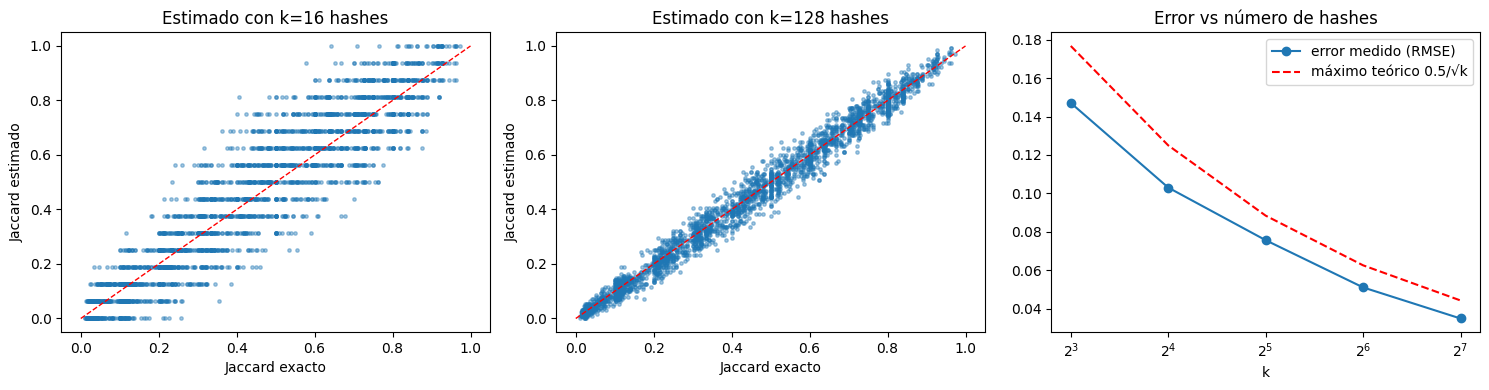

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, k in zip(ejes[:2], [16, 128]):
    eje.scatter(muestra_pares["jaccard"], muestra_pares[f"est_k{k}"], s=6, alpha=0.4)
    eje.plot([0, 1], [0, 1], "r--", lw=1)
    eje.set_title(f"Estimado con k={k} hashes"); eje.set_xlabel("Jaccard exacto"); eje.set_ylabel("Jaccard estimado")
ejes[2].plot(tabla_error["k"], tabla_error["rmse"], "o-", label="error medido (RMSE)")
ejes[2].plot(tabla_error["k"], 0.5 / np.sqrt(tabla_error["k"]), "r--", label="máximo teórico 0.5/√k")
ejes[2].set_xscale("log", base=2); ejes[2].set_title("Error vs número de hashes"); ejes[2].set_xlabel("k"); ejes[2].legend()
plt.tight_layout(); plt.show()

### Lectura de la tarea 6
- **Más hashes, menos error.** El error medio baja de 0.115 con k = 8 a 0.027 con k = 128. Con k = 128, el 95% de los pares tiene un error menor a 0.07. Con k = 16 ese valor es 0.20.
- **El error baja con la raíz de k.** Para reducirlo a la mitad hay que multiplicar los hashes por 4. Se ve al pasar de k = 16 (0.080) a k = 64 (0.040).
- **No todos los pares tienen el mismo error.** Es mayor cuando el Jaccard está cerca de 0.5 (0.10 con k = 16 y 0.034 con k = 128), y menor cerca de 0 y de 1. Es lo que predice la teoría: el error estándar es `sqrt(s(1-s)/k)` y es máximo en s = 0.5.
- **Conclusión:** con 128 hashes la estimación se equivoca en promedio unos 3 puntos de Jaccard. Sirve para encontrar candidatos, pero para decidir si un par supera un umbral conviene **verificarlo con el Jaccard exacto**, como hacemos en LSH.

In [15]:
# Archivos para la página web (módulo MinHash)
por_tramo = []
for k in K_LISTA:
    for tr, g in muestra_pares.groupby("tramo"):
        por_tramo.append({"k": k, "tramo_jaccard": f"{tr/10:.1f}-{(tr+1)/10:.1f}",
                          "error_medio": float((g[f"est_k{k}"] - g["jaccard"]).abs().mean()), "n_pares": int(len(g))})

guardar_json("minhash_error.json",
    {"titulo": "Error de MinHash según el número de funciones hash",
     "descripcion": "Diferencia absoluta entre el Jaccard exacto y el estimado con k hashes, medida en una muestra de pares del subconjunto.",
     "subconjunto": "Textos distintos de EsSalud",
     "n_pares_muestra": int(len(muestra_pares)),
     "campos": {"k": "número de funciones hash usadas", "error_medio": "promedio de |estimado - exacto|", "rmse": "raíz del error cuadrático medio",
                "error_p95": "el 95% de los pares tiene un error menor o igual a este valor", "tramo_jaccard": "rango del Jaccard exacto", "n_pares": "pares del tramo"},
     "formula_teorica": "error estándar = sqrt(s*(1-s)/k), donde s es el Jaccard exacto"},
    {"global": a_registros(tabla_error), "por_tramo": por_tramo})

guardar_json("minhash_pares.json",
    {"titulo": "Pares de textos: Jaccard exacto y estimado",
     "descripcion": "Muestra de pares con su Jaccard exacto y el estimado con distintos k. Sirve para dibujar exacto vs estimado.",
     "campos": {"jaccard_exacto": "Jaccard exacto", "est_kN": "Jaccard estimado con los primeros N hashes"}},
    a_registros(muestra_pares.drop(columns=["id_a", "id_b", "tramo"]).rename(columns={"jaccard": "jaccard_exacto"}).round(4)))

minhash_error.json: 2 registros, 6 KB
minhash_pares.json: 2759 registros, 328 KB


## 3. Tarea 7 — LSH: bandas, filas, falsos positivos y falsos negativos

### Cómo funciona (ejemplo mínimo)
La firma tiene 128 números. Con **b = 4 bandas** y **r = 2 filas** usamos solo 8 de ellos, agrupados así:

| banda 0 | banda 1 | banda 2 | banda 3 |
|---|---|---|---|
| números 1–2 | números 3–4 | números 5–6 | números 7–8 |

Dos textos son **candidatos** si **alguna banda completa coincide** en los dos. Para un par con Jaccard `s`:
- una banda coincide con probabilidad `s^r`,
- el par es candidato con probabilidad `1 - (1 - s^r)^b`,
- el umbral aproximado a partir del cual casi siempre es candidato es `(1/b)^(1/r)`.

**Más filas por banda** (r grande) → menos candidatos y más precisión, pero se pierden pares (falsos negativos).
**Menos filas** (r pequeño) → se encuentran casi todos los pares, pero con muchos candidatos falsos (falsos positivos).

- **Falso positivo (FP):** candidato cuyo Jaccard real es menor al umbral.
- **Falso negativo (FN):** par realmente similar que no llegó a ser candidato.

In [16]:
def candidatos(tabla, b, r):
    """Pares de textos que coinciden en al menos una banda completa (b bandas de r números cada una)."""
    bandas = (tabla.select("texto_id", F.explode(F.expr(
                  f"transform(sequence(0, {b-1}), i -> struct(i as banda, hash(slice(firma, i*{r}+1, {r})) as clave))")).alias("x"))
                   .select("texto_id", "x.banda", "x.clave"))
    p, q = bandas.alias("p"), bandas.alias("q")
    mismo_cubo = (F.col("p.banda") == F.col("q.banda")) & (F.col("p.clave") == F.col("q.clave")) & (F.col("p.texto_id") < F.col("q.texto_id"))
    return p.join(q, mismo_cubo).select(F.col("p.texto_id").alias("id_a"), F.col("q.texto_id").alias("id_b")).distinct()

### 3.1 Evaluar 10 combinaciones de bandas y filas sobre el subconjunto (donde conocemos la verdad exacta)

In [17]:
filas = []
for b, r in CONFIGS:
    t0 = time.time()
    cand = candidatos(S, b, r).join(pares, ["id_a", "id_b"], "left").fillna(0.0, ["jaccard"]).cache()    # Jaccard de cada candidato
    n_cand = cand.count()
    for t in UMBRALES:
        tp = cand.filter(F.col("jaccard") >= t).count()          # candidatos realmente similares
        filas.append({"bandas": b, "filas": r, "n_hashes": b * r, "umbral_efectivo": round((1 / b) ** (1 / r), 3), "umbral": t,
                      "candidatos": n_cand, "tp": tp, "fp": n_cand - tp, "fn": verdad[t] - tp,
                      "precision": tp / n_cand, "recall": tp / verdad[t]})
    cand.unpersist()
    print(f"b={b:3d} r={r:2d}  candidatos={n_cand:>9,}  ({time.time()-t0:.0f} s)")
grid = pd.DataFrame(filas)
grid[grid["umbral"] == 0.7].round(3)

b=128 r= 1  candidatos=4,406,642  (49 s)
b= 64 r= 2  candidatos=  692,855  (15 s)
b= 42 r= 3  candidatos=  107,099  (11 s)
b= 32 r= 4  candidatos=   22,802  (8 s)
b= 25 r= 5  candidatos=   10,748  (9 s)
b= 21 r= 6  candidatos=    6,998  (10 s)
b= 16 r= 8  candidatos=    2,677  (8 s)
b= 12 r=10  candidatos=    1,418  (9 s)
b= 10 r=12  candidatos=      917  (8 s)
b=  8 r=16  candidatos=      313  (9 s)


,bandas,filas,n_hashes,umbral_efectivo,umbral,candidatos,tp,fp,fn,precision,recall
2,128,1,128,0.008,0.7,4406642,1569,4405073,0,0.000,1.000
7,64,2,128,0.125,0.7,692855,1569,691286,0,0.002,1.000
12,42,3,126,0.288,0.7,107099,1569,105530,0,0.015,1.000
17,32,4,128,0.420,0.7,22802,1569,21233,0,0.069,1.000
22,25,5,125,0.525,0.7,10748,1566,9182,3,0.146,0.998
27,21,6,126,0.602,0.7,6998,1552,5446,17,0.222,0.989
32,16,8,128,0.707,0.7,2677,1330,1347,239,0.497,0.848
37,12,10,120,0.780,0.7,1418,1004,414,565,0.708,0.640
42,10,12,120,0.825,0.7,917,710,207,859,0.774,0.453
47,8,16,128,0.878,0.7,313,295,18,1274,0.942,0.188


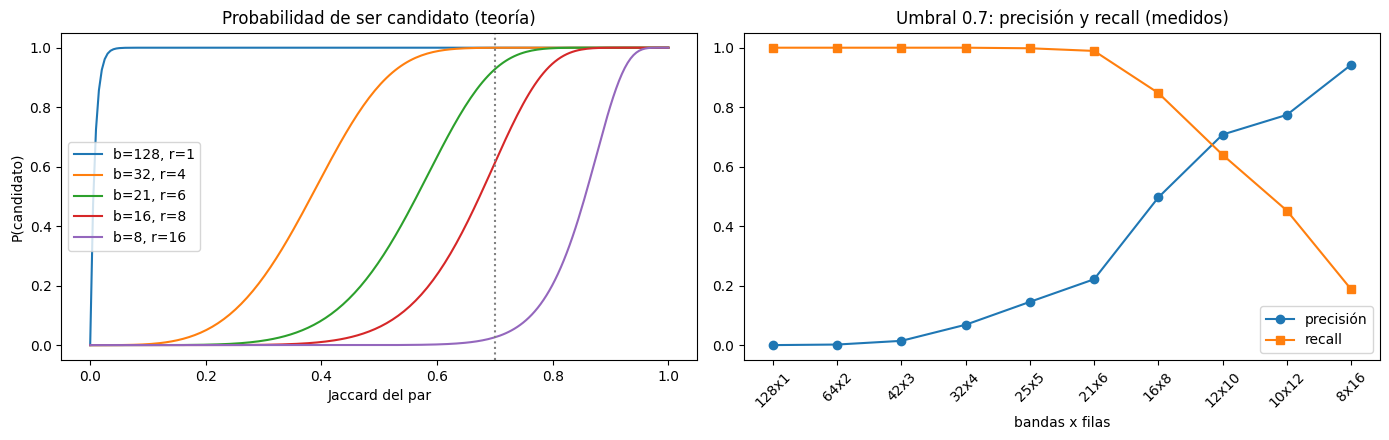

In [18]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
s = np.linspace(0, 1, 200)
for b, r in [(128, 1), (32, 4), (21, 6), (16, 8), (8, 16)]:
    ejes[0].plot(s, 1 - (1 - s ** r) ** b, label=f"b={b}, r={r}")
ejes[0].axvline(0.7, color="gray", ls=":"); ejes[0].set_title("Probabilidad de ser candidato (teoría)")
ejes[0].set_xlabel("Jaccard del par"); ejes[0].set_ylabel("P(candidato)"); ejes[0].legend()

g = grid[grid["umbral"] == 0.7]
x = np.arange(len(g)); etiquetas = [f"{b}x{r}" for b, r in zip(g["bandas"], g["filas"])]
ejes[1].plot(x, g["precision"], "o-", label="precisión"); ejes[1].plot(x, g["recall"], "s-", label="recall")
ejes[1].set_xticks(x); ejes[1].set_xticklabels(etiquetas, rotation=45); ejes[1].set_title("Umbral 0.7: precisión y recall (medidos)")
ejes[1].set_xlabel("bandas x filas"); ejes[1].legend()
plt.tight_layout(); plt.show()

### 3.2 Verificación cruzada con el MinHashLSH de Spark MLlib
MLlib trae su propio `approxSimilarityJoin`. Comprobamos que encuentra los mismos pares similares que la verdad exacta.

In [19]:
S_vec = df.join(textos_S, "texto").select("texto_id", "vec")
mllib = (modelo.approxSimilarityJoin(S_vec, S_vec, 0.3, distCol="distancia")      # distancia < 0.3  <=>  Jaccard > 0.7
              .filter("datasetA.texto_id < datasetB.texto_id"))
n_mllib = mllib.count()
n_exacto = pares.filter(F.col("jaccard") > 0.7).count()
print(f"pares con Jaccard > 0.7  ->  exactos: {n_exacto}  |  encontrados por MLlib: {n_mllib}")

pares con Jaccard > 0.7  ->  exactos: 1540  |  encontrados por MLlib: 1540


### 3.3 LSH sobre **todos** los textos (163 mil)
Con la configuración elegida (`LSH_FINAL`) buscamos pares similares en todo el conjunto, sin compararlos todos.
Cada candidato se verifica con el Jaccard exacto, y nos quedamos con los realmente similares.

In [20]:
b, r = LSH_FINAL
t0 = time.time()
cand_todos = candidatos(df, b, r)

izq = df.select(F.col("texto_id").alias("id_a"), F.col("ids").alias("ids_a"))
der = df.select(F.col("texto_id").alias("id_b"), F.col("ids").alias("ids_b"))
verificados = (cand_todos.join(izq, "id_a").join(der, "id_b")
                  .withColumn("comun", F.size(F.array_intersect("ids_a", "ids_b")))
                  .withColumn("jaccard", F.col("comun") / (F.size("ids_a") + F.size("ids_b") - F.col("comun")))
                  .select("id_a", "id_b", "jaccard"))
verificados.write.mode("overwrite").parquet(f"{SALIDA}/pares_verificados")
verificados = spark.read.parquet(f"{SALIDA}/pares_verificados").cache()

n_total = df.count()
resumen = {"bandas": b, "filas": r, "umbral_efectivo": round((1 / b) ** (1 / r), 3), "textos": n_total,
           "pares_posibles": n_total * (n_total - 1) // 2, "candidatos": verificados.count(), "segundos": round(time.time() - t0)}
resumen.update({f"similares_{int(t*100)}": verificados.filter(F.col("jaccard") >= t).count() for t in UMBRALES})
resumen["fraccion_comparada"] = resumen["candidatos"] / resumen["pares_posibles"]
pd.Series(resumen)

,0
bandas,2.100000e+01
filas,6.000000e+00
umbral_efectivo,6.020000e-01
textos,1.632080e+05
pares_posibles,1.331834e+10
candidatos,6.931440e+05
segundos,5.300000e+01
similares_50,2.333980e+05
similares_60,1.446060e+05
similares_70,7.142400e+04


### Lectura de la tarea 7
- **Hay un compromiso entre los dos errores.** Con filas pequeñas (por ejemplo 32 bandas x 4 filas) LSH encuentra todos los pares similares, pero genera 22,802 candidatos y solo el 7% lo es de verdad. Con filas grandes (8 x 16) casi todos los candidatos son buenos (94%), pero se pierde el 81% de los pares similares.
- **Los falsos positivos solo cuestan trabajo.** Como cada candidato se verifica con el Jaccard exacto, un falso positivo se descarta. Los **falsos negativos** son la pérdida real, porque nunca se revisan.
- **Elegimos 21 bandas x 6 filas** (umbral efectivo 0.60). Con umbral 0.7 pierde solo 17 de 1,569 pares (recall 0.989) y genera pocos candidatos. Con 16 x 8 se perderían 239.
- **Con todos los textos**, LSH revisó 693,144 pares candidatos. Son el 0.005% de los 13 mil millones de pares posibles. Encontró **71,424 pares con Jaccard ≥ 0.7**, 27,170 con ≥ 0.8 y 3,916 con ≥ 0.9.
- **La verificación cruzada con MLlib coincide:** encontró los mismos 1,540 pares que la verdad exacta. Aquí se cuenta Jaccard *mayor que* 0.7; la tabla de arriba usa *mayor o igual* a 0.7, por eso allí son 1,569.
- **Límite:** la precisión y el recall se midieron en un subconjunto (los textos de EsSalud). En otras entidades pueden variar.

In [21]:
# Archivos para la página web (módulo LSH)
guardar_json("lsh_grid.json",
    {"titulo": "LSH: bandas y filas frente a precisión y recall",
     "descripcion": "Para cada combinación de bandas y filas y cada umbral de similitud: candidatos, aciertos y errores, medidos contra el Jaccard exacto del subconjunto.",
     "subconjunto": "Textos distintos de EsSalud", "textos_subconjunto": int(n_S), "n_hashes_firma": N_HASH,
     "pares_verdaderos_por_umbral": {str(t): int(v) for t, v in verdad.items()},
     "campos": {"bandas": "número de bandas (b)", "filas": "filas por banda (r)", "n_hashes": "b*r, hashes usados de la firma",
                "umbral_efectivo": "aprox. (1/b)^(1/r)", "umbral": "Jaccard mínimo para considerar similar un par",
                "candidatos": "pares que coinciden en alguna banda", "tp": "candidatos realmente similares", "fp": "candidatos que no lo son (falsos positivos)",
                "fn": "pares similares que no fueron candidatos (falsos negativos)", "precision": "tp/candidatos", "recall": "tp/pares verdaderos"},
     "formula_teorica": "P(candidato) = 1 - (1 - s^r)^b"},
    a_registros(grid.round(4)))

guardar_json("lsh_resumen.json",
    {"titulo": "LSH con todos los textos", "descripcion": "Resultado de aplicar LSH a los textos distintos de las contrataciones.", "segundos_en_spark": resumen["segundos"]},
    [resumen])

lsh_grid.json: 50 registros, 10 KB
lsh_resumen.json: 1 registros, 0 KB


## 4. Tarea 8 — Interpretar casos concretos
Primero armamos, para cada texto, quién lo usó y cuándo (entidades, departamentos, fechas).

In [22]:
info = (procesos.groupBy("texto").agg(
            F.count("*").alias("n_procesos"), F.countDistinct("entidad_id").alias("n_entidades"),
            F.countDistinct("entidad_departamento").alias("n_departamentos"),
            F.mode("entidad").alias("entidad"), F.mode("entidad_departamento").alias("departamento"),
            F.date_format(F.min("fecha_pub"), "yyyy-MM-dd").alias("primera_fecha"), F.date_format(F.max("fecha_pub"), "yyyy-MM-dd").alias("ultima_fecha"),
            F.round(F.sum("valor_pen_valido")).alias("valor_total_pen")).cache())
info.count()

163221

### 4.1 Textos exactamente repetidos (compras recurrentes)
Los textos que aparecen en muchos procesos, sobre todo si los usan distintas entidades o en distintos años.

In [23]:
grupos = (info.filter("n_procesos > 1").orderBy(F.desc("n_procesos")).limit(100).toPandas())
grupos[["texto", "n_procesos", "n_entidades", "n_departamentos", "primera_fecha", "ultima_fecha"]].head(10)

,texto,n_procesos,n_entidades,n_departamentos,primera_fecha,ultima_fecha
0,servicio de supervision ambiental,550,1,1,2024-12-17,2025-03-26
1,servicio de fiscalizacion ambiental,221,1,1,2024-12-17,2025-03-24
2,tercero supervisor nivel iii titulado,188,1,1,2025-08-26,2026-08-21
3,servicio de evaluacion en temas ambientales,166,2,1,2024-12-18,2025-06-27
4,tercero supervisor titulado ingenieria ambiental,161,1,1,2024-06-10,2024-10-21
5,tercero supervisor nivel iv titulado,130,1,1,2025-08-26,2026-08-21
6,tercero fiscalizador titulado derecho,97,1,1,2024-06-04,2024-10-17
7,tercero fiscalizador bachiller derecho,82,1,1,2024-06-10,2024-10-18
8,servicio de tercero supervisor,78,1,1,2025-08-04,2026-07-13
9,tercero supervisor bachiller ingenieria ambiental,76,1,1,2024-06-10,2024-10-17


In [24]:
guardar_json("grupos_repetidos.json",
    {"titulo": "Textos que se repiten en muchos procesos", "descripcion": "Los 100 textos exactamente iguales que aparecen en más procesos.",
     "campos": {"texto": "descripción normalizada del proceso", "n_procesos": "procesos con ese texto", "n_entidades": "entidades distintas",
                "n_departamentos": "departamentos distintos", "entidad": "entidad que más lo usa", "departamento": "departamento de esa entidad",
                "primera_fecha": "primera publicación", "ultima_fecha": "última publicación", "valor_total_pen": "suma de montos en soles (sin los montos no disponibles)"}},
    a_registros(grupos))

grupos_repetidos.json: 100 registros, 32 KB


### 4.2 Pares casi iguales, pero no idénticos
Tomamos los pares con Jaccard entre 0.8 y 1 que encontró LSH, y vemos entre quiénes ocurren: la misma entidad, entidades distintas del mismo departamento, o de departamentos distintos.
Solo usamos textos que pertenecen a **una sola entidad**, para que la atribución sea clara.

In [25]:
textos_id = df.select("texto_id", "texto")
info_a = info.select([F.col(c).alias(f"{c}_a") for c in info.columns])      # texto_a, entidad_a, departamento_a, ...
info_b = info.select([F.col(c).alias(f"{c}_b") for c in info.columns])      # texto_b, entidad_b, departamento_b, ...

casos = (verificados.filter("jaccard >= 0.8 AND jaccard < 1")
            .join(textos_id.select(F.col("texto_id").alias("id_a"), F.col("texto").alias("texto_a")), "id_a")
            .join(textos_id.select(F.col("texto_id").alias("id_b"), F.col("texto").alias("texto_b")), "id_b")
            .join(info_a, "texto_a").join(info_b, "texto_b")
            .filter("n_entidades_a = 1 AND n_entidades_b = 1"))

tipo = (F.when(F.col("entidad_a") == F.col("entidad_b"), "misma_entidad")
         .when(F.col("departamento_a") == F.col("departamento_b"), "mismo_departamento")
         .otherwise("departamentos_distintos"))
casos = casos.withColumn("tipo_caso", tipo).cache()
resumen_casos = casos.groupBy("tipo_caso").count().toPandas()
resumen_casos["%"] = (100 * resumen_casos["count"] / resumen_casos["count"].sum()).round(1)
resumen_casos

,tipo_caso,count,%
0,misma_entidad,26050,96.6
1,departamentos_distintos,640,2.4
2,mismo_departamento,282,1.0


In [26]:
# Dos ejemplos de cada tipo, para leerlos
pd.set_option("display.max_colwidth", 120)
for t in ["misma_entidad", "mismo_departamento", "departamentos_distintos"]:
    print("\n=====", t, "=====")
    for r in casos.filter(F.col("tipo_caso") == t).orderBy(F.hash("id_a", "id_b")).limit(2).collect():
        print(f"Jaccard {r['jaccard']:.2f} | {r['entidad_a']} ({r['departamento_a']}) vs {r['entidad_b']} ({r['departamento_b']})")
        print("   A:", r["texto_a"][:150]); print("   B:", r["texto_b"][:150])


===== misma_entidad =====
Jaccard 0.82 | MUNICIPALIDAD DISTRITAL DE MAZAMARI (JUNIN) vs MUNICIPALIDAD DISTRITAL DE MAZAMARI (JUNIN)
   A: adquisicion de abono organico concentrado x 50 kg para el proyecto mejoramiento sostenible de cultivo de cafes especiales mediante sistemas agroforest
   B: adquisicion de abono organico concentrado x 50 kg para el proyecto mejoramiento sostenible de cultivo de cafes especiales meiante sistemas agroforesta
Jaccard 0.85 | GOBIERNO REGIONAL DE SAN MARTIN Sede Central (SAN MARTIN) vs GOBIERNO REGIONAL DE SAN MARTIN Sede Central (SAN MARTIN)
   A: contratacion del servicio de consultoria de obra para la supervision de la ejecucion del proyecto mejoramiento y ampliacion del servicio educativo en 
   B: servicio de consultoria de obra para la contratacion del saldo de la supervision de la ejecucion del proyecto mejoramiento y ampliacion del servicio e

===== mismo_departamento =====
Jaccard 0.80 | CONSEJO NACIONAL DE CIENCIA, TECNOLOGIA E INNOVACION TECNO

In [27]:
elegidos = (casos.withColumn("n", F.row_number().over(Window.partitionBy("tipo_caso").orderBy(F.hash("id_a", "id_b")))).filter("n <= 20")
                 .select("tipo_caso", F.round("jaccard", 3).alias("jaccard"), "texto_a", "texto_b", "entidad_a", "entidad_b",
                         "departamento_a", "departamento_b", "primera_fecha_a", "primera_fecha_b", "n_procesos_a", "n_procesos_b").toPandas())
guardar_json("casos_similares.json",
    {"titulo": "Pares de textos casi iguales", "descripcion": "Ejemplos de pares con Jaccard entre 0.8 y 1 (sin incluir los idénticos), 20 por cada tipo de caso.",
     "campos": {"tipo_caso": "misma_entidad, mismo_departamento o departamentos_distintos", "jaccard": "similitud exacta",
                "texto_a / texto_b": "descripciones normalizadas", "entidad_a / entidad_b": "entidad contratante", "departamento_a / departamento_b": "sede de la entidad",
                "primera_fecha_a / primera_fecha_b": "primera publicación del texto", "n_procesos_a / n_procesos_b": "procesos con ese texto"},
     "nota": "No incluye nombres de proveedores ni de postores."},
    a_registros(elegidos))

casos_similares.json: 60 registros, 40 KB


### Interpretación de los casos
**1. Textos exactamente repetidos.** Los textos que más se repiten son del **Organismo de Evaluación y Fiscalización Ambiental (OEFA)**, en Lima. En los 8 primeros siempre es la misma entidad, salvo el cuarto, que lo usan 2 entidades. El primero, "servicio de supervision ambiental", aparece en 550 procesos entre diciembre de 2024 y marzo de 2025.
Lo más probable es que sean muchas contrataciones individuales con una descripción genérica. **El texto no dice qué se compró, a quién ni por cuánto.** Para saber si hay fraccionamiento harían falta el monto, la fecha y el proveedor.

**2. Pares casi iguales (Jaccard entre 0.8 y 1).** LSH encontró 27,170 pares con Jaccard de 0.8 o más. Aquí analizamos los que no son idénticos (Jaccard menor que 1) y cuyos dos textos pertenecen a **una sola entidad cada uno**: 26,972 pares.
- el **96.6%** ocurre **dentro de la misma entidad** (26,050 pares),
- el 2.4% entre entidades de departamentos distintos (640 pares),
- el 1.0% entre entidades del mismo departamento (282 pares).

**Qué significan los pares dentro de una misma entidad.** Suelen ser compras en serie o renovaciones que cambian un dato. Por ejemplo, el Jurado Nacional de Elecciones alquila un inmueble para la oficina de cada jurado electoral especial y solo cambia el lugar (Angaraes, Huaytará...). Otros casos probables son los que cambian el periodo o el destino de la compra. En esta tabla no medimos cuántos son de cada clase.

También hay errores de tipeo. En un ejemplo de la Municipalidad de Mazamari, uno de los textos trae "meiante" en vez de "mediante".

**Qué significan los pares entre entidades distintas.** Parecen **plantillas**: la misma redacción con el nombre de la entidad cambiado. Por ejemplo, "adquisicion de servidor para el centro de datos del concytec" y "...del pronabec", o la compra de suministro de alimentos para el vaso de leche de dos municipalidades del Cusco. Son una minoría (3.4%), pero muestran lenguaje estandarizado en todo el país.

**Qué NO se puede concluir.** Un texto parecido no prueba una irregularidad. Puede ser una plantilla, una compra recurrente o un error de digitación. Esta técnica sirve para **agrupar compras de un mismo tipo, limpiar duplicados y seleccionar casos para que una persona los revise**, pero no para acusar a nadie. Al publicar estos hallazgos hay que decirlo.

**Límites.** Solo se compara el texto, no los montos, las fechas ni los proveedores. Los 20 casos de cada tipo que van a la web son una muestra balanceada, **no proporcional** (en los datos reales dominan los pares de la misma entidad).

## 5. Metadatos para la página web

In [28]:
guardar_json("metadata.json",
    {"titulo": "Metadatos del módulo de similitud", "descripcion": "Parámetros usados y tamaños, para citar en la página."},
    [{"textos_distintos": int(n_unicos), "textos_usados": int(n_usados), "procesos": int(procesos.count()),
      "shingle": "pares de palabras seguidas", "n_hashes_firma": N_HASH, "semilla": SEED,
      "subconjunto_evaluacion": "textos distintos de EsSalud", "textos_subconjunto": int(n_S),
      "lsh_final": {"bandas": LSH_FINAL[0], "filas": LSH_FINAL[1]}, "spark": spark.version}])
print(sorted(os.listdir(WEB)))

metadata.json: 1 registros, 0 KB
['casos_similares.json', 'grupos_repetidos.json', 'lsh_grid.json', 'lsh_resumen.json', 'metadata.json', 'minhash_error.json', 'minhash_pares.json']
